# A Tour of Regression Models — Energy Forecasting Edition (Open Power System Data)

Same lineup again: **Linear Regression → Ridge/Lasso/Elastic Net → MLP → Random
Forest → XGBoost → CatBoost → LightGBM**, each tuned via `RandomizedSearchCV` with a compact parameter search.

**Dataset:** [Open Power Systems Data](https://www.kaggle.com/datasets/jordansiem/open-power-systems-data)
(Kaggle, `jordansiem/...`, originally published by [Open Power System Data](https://open-power-system-data.org/))
— Germany's national **daily** electricity consumption, wind generation, and
solar generation, 2006–2017 (4,383 days).

**What's new here vs. the PJM notebook:** PJM was *purely* univariate — one
column, hourly. This dataset is **daily** (a full order of magnitude coarser
cadence, so the lag windows change) and comes with two **real covariates** — wind
and solar generation — that PJM didn't have. Both covariates are genuinely,
structurally missing for part of the series (solar metering started later than
wind metering in the source data), which is the same "missing by source, not at
random" situation the credit-risk notebook's `MonthlyIncome` flag handled, now in
a time-series setting.


## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit, GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, RidgeCV, LassoCV, ElasticNetCV
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


Searches use two candidates and two cross-validation folds. Every selected model refits on the complete training partition.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, RidgeCV, LassoCV, ElasticNetCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


np.random.seed(42)


## 2. Load and clean the data

`Wind`, `Solar`, and `Wind+Solar` are missing for roughly a third to half of the
series — not at random, but because Germany's renewable-generation metering
expanded over time (solar metering in particular started later than wind). We
handle this the same way the credit-risk notebook handled `MonthlyIncome`:
impute (here, with 0 — "not yet metered" is closer to "not yet generating much,
at national scale, this early" than to any particular average value) and add an
explicit missing-indicator flag per column, so models can tell "zero generation"
apart from "no data available."


In [3]:
raw = pd.read_csv("open_power_systems_data.csv", parse_dates=["Date"])
raw = raw.sort_values("Date").set_index("Date")
raw = raw.asfreq("D")  # ensure no implicit date gaps

print(raw.shape)

print(raw.head())
print(raw.tail())

print(raw.isna().sum())

raw.describe()


(4383, 4)
            Consumption  Wind  Solar  Wind+Solar
Date                                            
2006-01-01     1069.184   NaN    NaN         NaN
2006-01-02     1380.521   NaN    NaN         NaN
2006-01-03     1442.533   NaN    NaN         NaN
2006-01-04     1457.217   NaN    NaN         NaN
2006-01-05     1477.131   NaN    NaN         NaN
            Consumption     Wind   Solar  Wind+Solar
Date                                                
2017-12-27   1263.94091  394.507  16.530     411.037
2017-12-28   1299.86398  506.424  14.162     520.586
2017-12-29   1295.08753  584.277  29.854     614.131
2017-12-30   1215.44897  721.247   7.467     728.714
2017-12-31   1107.11488  721.176  19.980     741.156
Consumption       0
Wind           1463
Solar          2195
Wind+Solar     2196
dtype: int64


,Consumption,Wind,Solar,Wind+Solar
count,4383.000000,2920.000000,2188.000000,2187.000000
mean,1338.675836,164.814173,89.258695,272.663481
std,165.775710,143.692732,58.550099,146.319884
min,842.395000,5.757000,1.968000,21.478000
25%,1217.859000,62.353250,35.179250,172.185500
50%,1367.123000,119.098000,86.407000,240.991000
75%,1457.761000,217.900250,135.071500,338.988000
max,1709.568000,826.278000,241.580000,851.556000


In [4]:
df = raw.copy()
for col in ["Wind", "Solar", "Wind+Solar"]:
    df[f"{col}_missing"] = df[col].isna().astype(int)
    df[col] = df[col].fillna(0.0)

df["Consumption"] = df["Consumption"].interpolate(method="time")  # the target itself has no gaps, but be safe

print(f"Final shape: {df.shape}")
df.head()


Final shape: (4383, 7)


,Consumption,Wind,Solar,Wind+Solar,Wind_missing,Solar_missing,Wind+Solar_missing
Date,,,,,,,
2006-01-01,1069.184,0.0,0.0,0.0,1,1,1
2006-01-02,1380.521,0.0,0.0,0.0,1,1,1
2006-01-03,1442.533,0.0,0.0,0.0,1,1,1
2006-01-04,1457.217,0.0,0.0,0.0,1,1,1
2006-01-05,1477.131,0.0,0.0,0.0,1,1,1


### Quick EDA

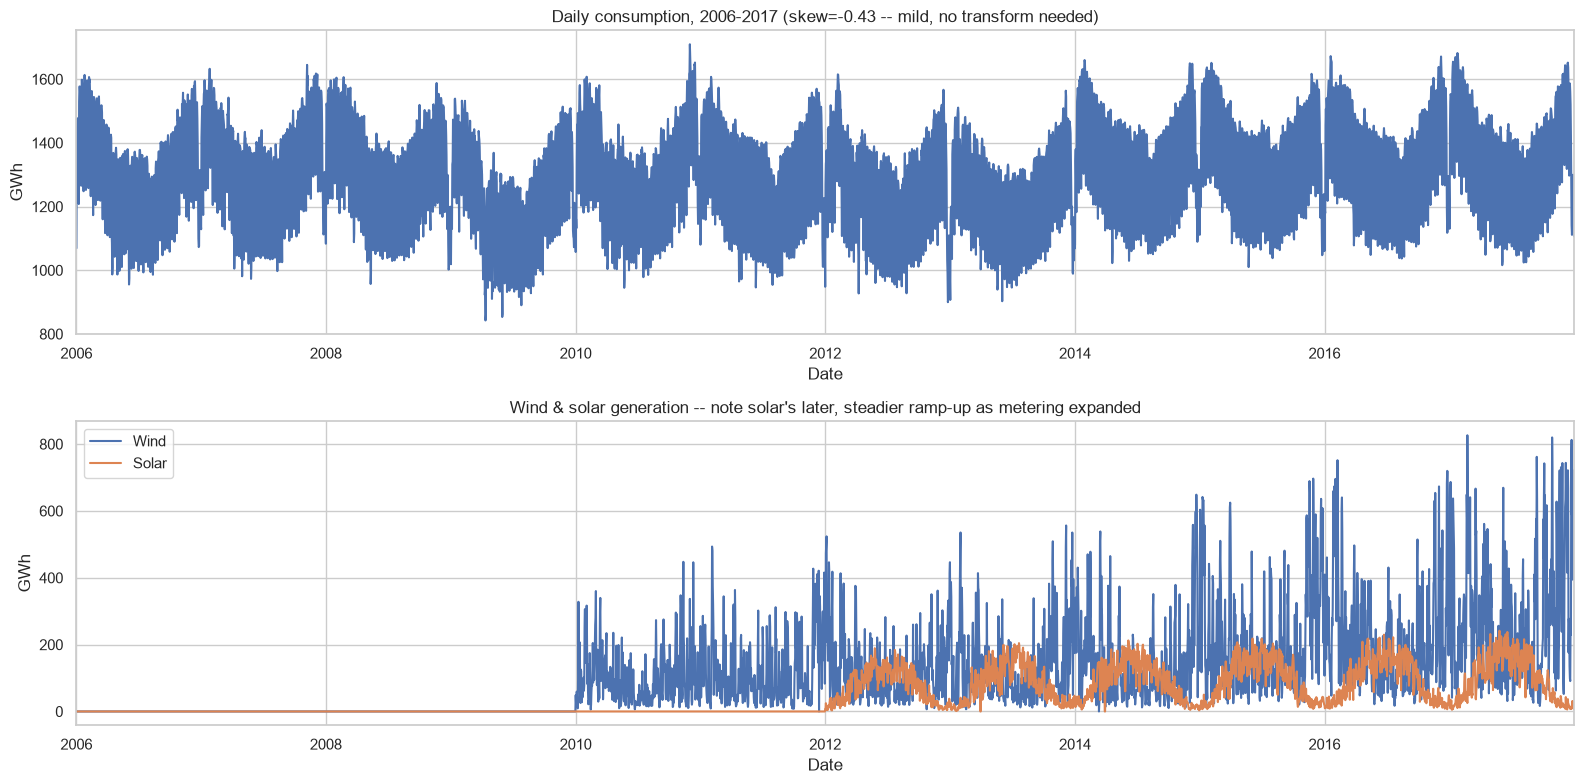

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(16, 8))

df["Consumption"].plot(ax=axes[0])
axes[0].set_title(f"Daily consumption, 2006-2017 (skew={df['Consumption'].skew():.2f} -- mild, no transform needed)")
axes[0].set_ylabel("GWh")

df[["Wind", "Solar"]].plot(ax=axes[1])
axes[1].set_title("Wind & solar generation -- note solar's later, steadier ramp-up as metering expanded")
axes[1].set_ylabel("GWh")

plt.tight_layout()
plt.show()


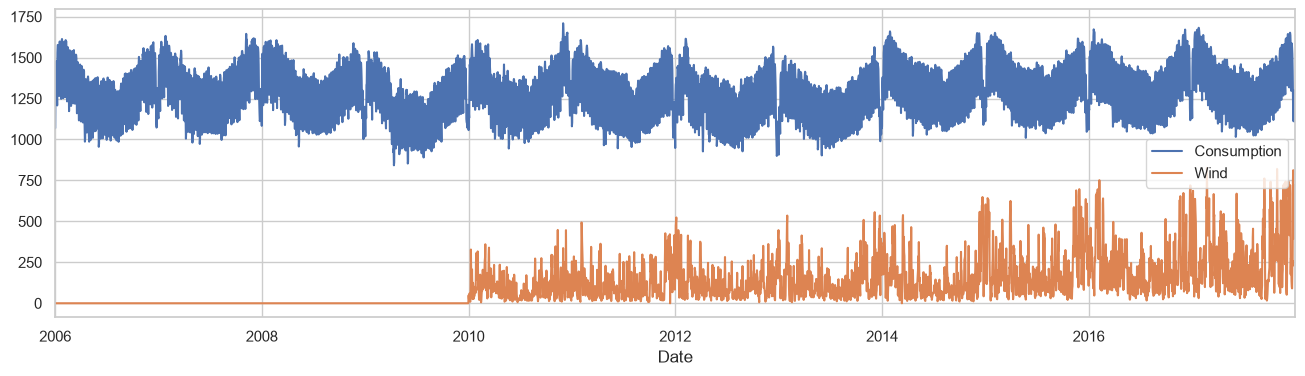

In [6]:
# The figure size is not being applied because plt.figure(...) creates a new figure,
# but then df[["Consumption", "Wind"]].plot() creates and returns its own figure and axes,
# ignoring the previously set figure size.
# To explicitly set the figure size for the pandas plot, pass figsize to the plot() call:
df[["Consumption", "Wind"]].plot(figsize=(16, 4))
plt.show()


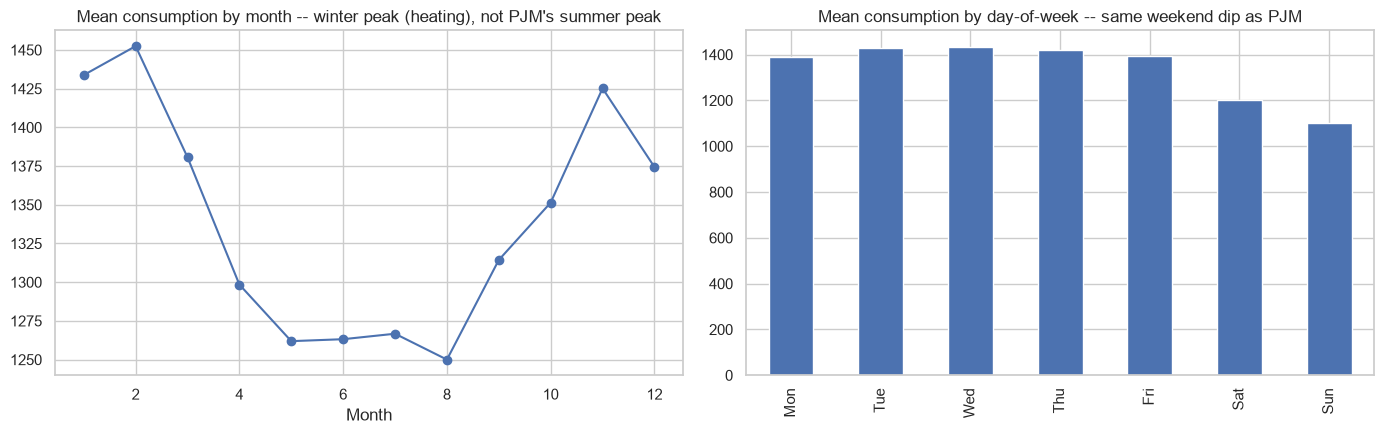

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

monthly = df.groupby(df.index.month)["Consumption"].mean()
monthly.plot(kind="line", marker="o", ax=axes[0])
axes[0].set_title("Mean consumption by month -- winter peak (heating), not PJM's summer peak")
axes[0].set_xlabel("Month")

dow = df.groupby(df.index.dayofweek)["Consumption"].mean()
dow.index = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]
dow.plot(kind="bar", ax=axes[1])
axes[1].set_title("Mean consumption by day-of-week -- same weekend dip as PJM")

plt.tight_layout()
plt.show()


Germany's seasonal pattern **inverts** PJM's: a **winter peak**, not a summer
one — consistent with a heating-dominated (not air-conditioning-dominated) national
climate and demand mix. The weekend dip is the same stylized fact as PJM, for the
same underlying reason (lower commercial/industrial activity).


             Consumption      Wind     Solar  Wind+Solar
Consumption     1.000000  0.116378 -0.095165    0.054281
Wind            0.116378  1.000000  0.220947    0.846380
Solar          -0.095165  0.220947  1.000000    0.615274
Wind+Solar      0.054281  0.846380  0.615274    1.000000


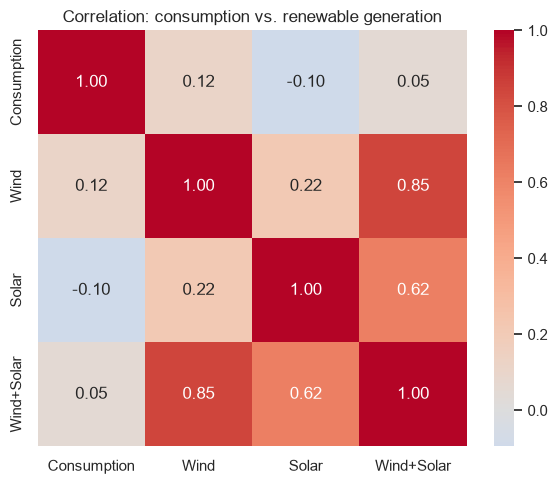

In [8]:
corr = df[["Consumption", "Wind", "Solar", "Wind+Solar"]].corr()

print(corr)
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation: consumption vs. renewable generation")
plt.tight_layout()
plt.show()


Wind/solar generation correlate only weakly with consumption — expected,
since generation is driven by weather, and consumption by demand/calendar
factors; the two are only loosely linked (e.g., both have a seasonal component,
but for different physical reasons). Don't expect these two covariates to be
major predictive features once lag/calendar features are in the mix — a useful,
realistic contrast to assuming every available covariate must be powerful.


### Feature engineering

Daily data needs different lag windows than PJM's hourly data: **1 day**, **7
days** (same day last week), and **365 days** (same day last year, capturing
annual seasonality directly as a lag rather than relying only on `month`).


In [9]:
feat = df.copy()
feat["dayofweek"] = feat.index.dayofweek
feat["month"] = feat.index.month
feat["is_weekend"] = (feat["dayofweek"] >= 5).astype(int)

for lag in [1, 7, 365]:
    feat[f"lag_{lag}"] = feat["Consumption"].shift(lag)

feat["rolling_mean_7"] = feat["Consumption"].shift(1).rolling(7).mean()
feat["rolling_mean_30"] = feat["Consumption"].shift(1).rolling(30).mean()

before = len(feat)
feat = feat.dropna().reset_index()
print(f"Rows before -> after dropping the initial year with no full lag_365 history: "
      f"{before} -> {len(feat)}")

numeric_features = ["dayofweek", "month", "is_weekend", "Wind", "Solar",
                     "Wind_missing", "Solar_missing",
                     "lag_1", "lag_7", "lag_365", "rolling_mean_7", "rolling_mean_30"]

X = feat[numeric_features]
y = feat["Consumption"]

feat[numeric_features + ["Consumption"]].describe()


Rows before -> after dropping the initial year with no full lag_365 history: 4383 -> 4018


,dayofweek,month,is_weekend,Wind,Solar,Wind_missing,Solar_missing,lag_1,lag_7,lag_365,rolling_mean_7,rolling_mean_30,Consumption
count,4018.000000,4018.000000,4018.000000,4018.000000,4018.000000,4018.000000,4018.000000,4018.000000,4018.000000,4018.000000,4018.000000,4018.000000,4018.000000
mean,3.000000,6.522648,0.285714,119.775357,48.605780,0.273270,0.455450,1338.572657,1338.558869,1334.663967,1338.572864,1338.437247,1338.563378
std,2.000249,3.449210,0.451810,142.827532,61.990707,0.445694,0.498073,166.176286,166.204857,165.301876,100.706051,88.555595,166.188172
min,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,842.395000,842.395000,842.395000,986.947429,1121.961700,842.395000
25%,1.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1216.055500,1216.154500,1214.792500,1270.665000,1277.347942,1216.055500
50%,3.000000,7.000000,0.000000,74.686000,14.457500,0.000000,0.000000,1368.580000,1368.580000,1363.080000,1331.147929,1330.223650,1368.580000
75%,5.000000,10.000000,1.000000,175.053750,95.029250,1.000000,1.000000,1457.346250,1457.346250,1454.684250,1410.223214,1399.401958,1457.346250
max,6.000000,12.000000,1.000000,826.278000,241.580000,1.000000,1.000000,1709.568000,1709.568000,1709.568000,1584.605714,1554.624100,1709.568000


## 3. Time-aware train/test split

Same reasoning as every time-series notebook in this series: chronological
split, `TimeSeriesSplit` for every cross-validation fold below. We hold out the
final 2 years as test.


In [10]:
cutoff = X.shape[0] - 365 * 2
X_train, X_test = X.iloc[:cutoff], X.iloc[cutoff:]
y_train, y_test = y.iloc[:cutoff], y.iloc[cutoff:]
dates_test = feat["Date"].iloc[cutoff:]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

tscv = TimeSeriesSplit(n_splits=2)

print(f"Train: {X_train.shape} ({feat['Date'].iloc[0].date()} to {feat['Date'].iloc[cutoff-1].date()})")
print(f"Test:  {X_test.shape} ({feat['Date'].iloc[cutoff].date()} to {feat['Date'].iloc[-1].date()})")


Train: (3288, 12) (2007-01-01 to 2016-01-01)
Test:  (730, 12) (2016-01-02 to 2017-12-31)


In [11]:
results = {}

def evaluate(name, y_true, y_pred):
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mape = (np.abs((y_true - y_pred) / y_true)).mean() * 100
    mape2 = mean_absolute_percentage_error(y_true, y_pred) * 100
    results[name] = {"RMSE": rmse, "MAE": mae, "R2": r2, "MAPE_%": mape}
    print(f"{name:16s}  RMSE={rmse:.1f}   MAE={mae:.1f}   R2={r2:.4f}   MAPE={mape:.2f}%, MAPE2={mape2:.2f}%")
    return rmse, mae, r2


## 4. Linear Regression


In [12]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)
y_pred_lr = lin_reg.predict(X_test_scaled)
evaluate("LinearRegression", y_test, y_pred_lr)


LinearRegression  RMSE=55.1   MAE=34.1   R2=0.8838   MAPE=2.57%, MAPE2=2.57%


(55.10910990260637, 34.13112474140186, 0.8837960983233141)

In [13]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)
y_pred_lr = lin_reg.predict(X_test_scaled)
evaluate("LR", y_test, y_pred_lr)


LR                RMSE=55.1   MAE=34.1   R2=0.8838   MAPE=2.57%, MAPE2=2.57%


(55.10910990260637, 34.13112474140186, 0.8837960983233141)

In [14]:
print(lin_reg.coef_)


[-55.47062713  -4.06371442 -76.46397097  -1.04089378  -4.25984326
  -3.55661759  -2.20152015  50.77322359 -17.85319323  14.41763762
  63.58970806   1.87014647]


/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98108/746690973.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")


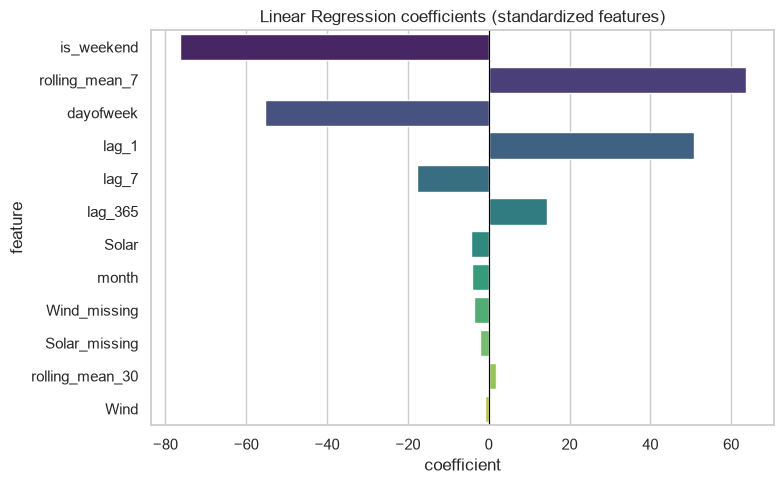

,feature,coefficient
2,is_weekend,-76.463971
10,rolling_mean_7,63.589708
0,dayofweek,-55.470627
7,lag_1,50.773224
8,lag_7,-17.853193
9,lag_365,14.417638
4,Solar,-4.259843
1,month,-4.063714
5,Wind_missing,-3.556618
6,Solar_missing,-2.201520


In [15]:
coef_df = pd.DataFrame({"feature": numeric_features, "coefficient": lin_reg.coef_}
                       ).sort_values("coefficient", key=abs, ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")
plt.title("Linear Regression coefficients (standardized features)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()
coef_df


## 5. Regularized Linear Models: Ridge, Lasso & Elastic Net


In [16]:
alphas = np.logspace(-2, 2, 3)

ridge = RidgeCV(alphas=alphas, cv=tscv)
ridge.fit(X_train_scaled, y_train)
y_pred_ridge = ridge.predict(X_test_scaled)
evaluate("Ridge", y_test, y_pred_ridge)
print(f"Chosen alpha: {ridge.alpha_:.4f}")


Ridge             RMSE=55.1   MAE=34.1   R2=0.8838   MAPE=2.57%, MAPE2=2.57%
Chosen alpha: 0.0100


In [17]:
lasso = LassoCV(alphas=alphas, cv=tscv, max_iter=5000, random_state=RANDOM_STATE)
lasso.fit(X_train_scaled, y_train)
y_pred_lasso = lasso.predict(X_test_scaled)
evaluate("Lasso", y_test, y_pred_lasso)
print(f"Chosen alpha: {lasso.alpha_:.4f}")
print(f"Features zeroed out: {(lasso.coef_ == 0).sum()} / {len(lasso.coef_)}")


Lasso             RMSE=56.2   MAE=34.9   R2=0.8790   MAPE=2.62%, MAPE2=2.62%
Chosen alpha: 1.0000
Features zeroed out: 4 / 12


In [18]:
elastic = ElasticNetCV(alphas=alphas, l1_ratio=[.5],
                        cv=tscv, max_iter=5000, random_state=RANDOM_STATE)
elastic.fit(X_train_scaled, y_train)
y_pred_elastic = elastic.predict(X_test_scaled)
evaluate("ElasticNet", y_test, y_pred_elastic)
print(f"Chosen alpha: {elastic.alpha_:.4f}, l1_ratio: {elastic.l1_ratio_:.2f}")
print(f"Features zeroed out: {(elastic.coef_ == 0).sum()} / {len(elastic.coef_)}")


ElasticNet        RMSE=55.2   MAE=34.3   R2=0.8834   MAPE=2.58%, MAPE2=2.58%
Chosen alpha: 0.0100, l1_ratio: 0.50
Features zeroed out: 0 / 12


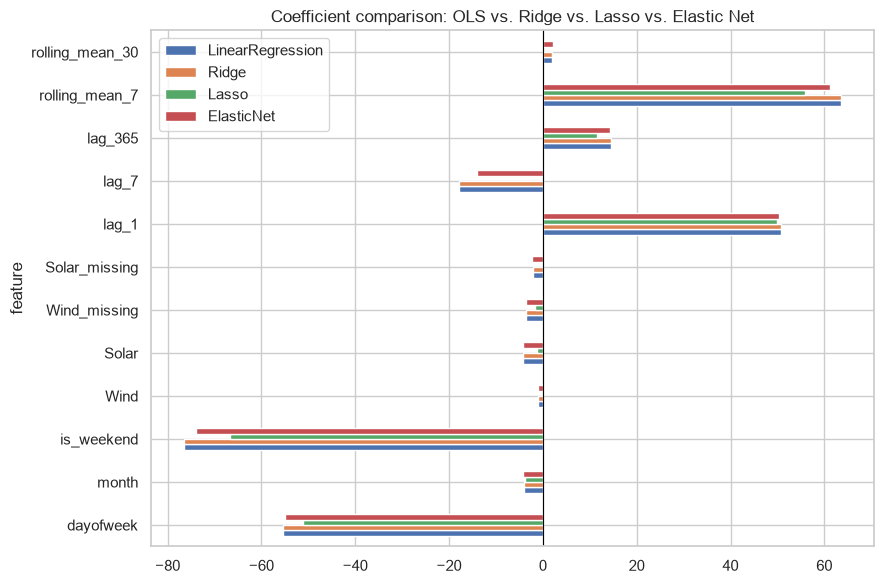

,LinearRegression,Ridge,Lasso,ElasticNet
feature,,,,
dayofweek,-55.470627,-55.470299,-51.086070,-54.912755
month,-4.063714,-4.063802,-3.804520,-4.195241
is_weekend,-76.463971,-76.462354,-66.803267,-73.938884
Wind,-1.040894,-1.040894,0.000000,-1.020076
Solar,-4.259843,-4.259902,-1.255935,-4.321942
Wind_missing,-3.556618,-3.556599,-1.576864,-3.515413
Solar_missing,-2.201520,-2.201572,-0.000000,-2.253236
lag_1,50.773224,50.772922,49.847439,50.266473
lag_7,-17.853193,-17.850806,-0.000000,-14.083235


In [19]:
coef_compare = pd.DataFrame({
    "feature": numeric_features, "LinearRegression": lin_reg.coef_,
    "Ridge": ridge.coef_, "Lasso": lasso.coef_, "ElasticNet": elastic.coef_,
}).set_index("feature")
coef_compare.plot(kind="barh", figsize=(9, 6))
plt.title("Coefficient comparison: OLS vs. Ridge vs. Lasso vs. Elastic Net")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()
coef_compare


Watch whether `Wind`/`Solar` survive Lasso/Elastic Net's feature selection —
given their weak correlation with the target from the EDA step, a reasonable bet
is that at least one gets zeroed out in favor of the lag/calendar features.


## 6. K-Nearest Neighbors (KNN)

A genuinely different kind of model from everything else in this notebook: KNN
has no coefficients and builds no trees. It predicts a point's target by
averaging the targets of its `k` nearest training points in feature space —
"nearest" measured on the *scaled* features (the same `X_train_scaled`/
`X_test_scaled` used by the linear models and MLP above), since distance is
meaningless once features sit on wildly different raw scales.

**When to reach for it:** a quick, assumption-light baseline — no linearity, no
tree-splittable structure, nothing learned at "training" time (there's no
training at all; `.fit()` just stores the data).

**Key hyperparameters:**
- `n_neighbors` (k): more neighbors → smoother, more biased predictions; fewer →
  noisier, more variance.
- `weights`: `"uniform"` averages neighbors equally; `"distance"` weights closer
  neighbors more heavily.
- `p`: the distance metric's power — `1` = Manhattan, `2` = Euclidean.

**Limitations:** prediction is slow on large datasets (every query compares
against the full training set); accuracy degrades in high dimensions (the
"curse of dimensionality" — with enough dimensions, every point ends up roughly
equidistant from every other).


In [20]:
knn = KNeighborsRegressor(n_neighbors=15, weights="distance", p=1)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
evaluate("KNN", y_test, y_pred_knn)


KNN               RMSE=54.0   MAE=30.9   R2=0.8883   MAPE=2.32%, MAPE2=2.32%


(54.023563194926076, 30.857072032988917, 0.8883290096621802)

### Hyperparameter tuning with `GridSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [21]:
knn_param_grid = {'n_neighbors': [5, 15], 'weights': ['distance'], 'p': [2]}

knn_grid = GridSearchCV(
    KNeighborsRegressor(),
    param_grid=knn_param_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
)
knn_grid.fit(X_train_scaled, y_train)

print(f"Best params: {knn_grid.best_params_}")
print(f"Best CV RMSE: {-knn_grid.best_score_:.4f}")


Best params: {'n_neighbors': 15, 'p': 2, 'weights': 'distance'}
Best CV RMSE: 68.7714


In [22]:
y_pred_knn_tuned = knn_grid.best_estimator_.predict(X_test_scaled)
evaluate("KNN (tuned)", y_test, y_pred_knn_tuned)


KNN (tuned)       RMSE=56.7   MAE=33.5   R2=0.8770   MAPE=2.51%, MAPE2=2.51%


(56.69762211672362, 33.49819345446784, 0.8770004260057818)

## 7. MLP (Multi-Layer Perceptron)


In [23]:
mlp = MLPRegressor(hidden_layer_sizes=(128, 64), activation="relu", alpha=1e-4,
                    learning_rate_init=1e-3, max_iter=1000, early_stopping=True,
                    n_iter_no_change=10, random_state=RANDOM_STATE)
mlp.fit(X_train_scaled, y_train)
y_pred_mlp = mlp.predict(X_test_scaled)
evaluate("MLP", y_test, y_pred_mlp)


MLP               RMSE=50.4   MAE=28.6   R2=0.9029   MAPE=2.17%, MAPE2=2.17%


(50.36941955482558, 28.591562269360736, 0.9029249082973939)

### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [24]:
mlp_param_dist = {'hidden_layer_sizes': [(64, 32)], 'alpha': [0.0001, 0.001]}


mlp_search = RandomizedSearchCV(
    MLPRegressor(activation="relu", learning_rate_init=1e-3, max_iter=1000,
                 early_stopping=True, n_iter_no_change=15, random_state=RANDOM_STATE),
    param_distributions=mlp_param_dist, n_iter=2, cv=tscv,
    scoring="neg_root_mean_squared_error", n_jobs=2, random_state=RANDOM_STATE,
)
mlp_search.fit(X_train_scaled, y_train)
print(f"Best params: {mlp_search.best_params_}")
print(f"Best CV RMSE: {-mlp_search.best_score_:.1f}")


Best params: {'hidden_layer_sizes': (64, 32), 'alpha': 0.001}
Best CV RMSE: 489.7


In [25]:
y_pred_mlp_tuned = mlp_search.best_estimator_.predict(X_test_scaled)
evaluate("MLP (tuned)", y_test, y_pred_mlp_tuned)


MLP (tuned)       RMSE=52.8   MAE=30.3   R2=0.8934   MAPE=2.29%, MAPE2=2.29%


(52.77832401646748, 30.31615413327778, 0.8934176952740258)

In [26]:
mlp_model= MLPRegressor(hidden_layer_sizes=(128,64), max_iter=1000, n_iter_no_change=10,early_stopping=True,random_state=RANDOM_STATE)
mlp_model.fit(X_train_scaled, y_train)
y_predict = mlp_model.predict(X_test_scaled)
evaluate("MLP", y_test, y_predict )


MLP               RMSE=50.4   MAE=28.6   R2=0.9029   MAPE=2.17%, MAPE2=2.17%


(50.36941955482558, 28.591562269360736, 0.9029249082973939)

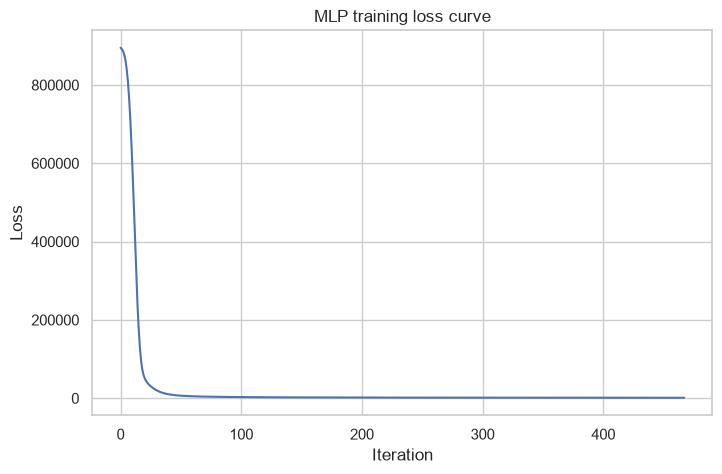

In [27]:
plt.plot(mlp.loss_curve_)
plt.title("MLP training loss curve")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()


<function matplotlib.pyplot.show(close=None, block=None)>

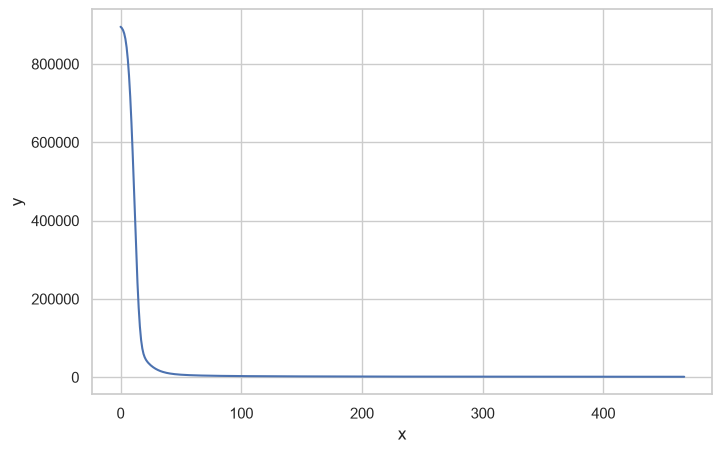

In [28]:
plt.plot(mlp_model.loss_curve_)
plt.ylabel("Training loss")
plt.xlabel("Iteration")
plt.show()


## 8. Random Forest


In [29]:
rf = RandomForestRegressor(n_estimators=300, max_depth=None, min_samples_leaf=2,
                            n_jobs=2, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
evaluate("RandomForest", y_test, y_pred_rf)


RandomForest      RMSE=44.7   MAE=23.9   R2=0.9234   MAPE=1.81%, MAPE2=1.81%


(44.734797950621335, 23.855417204029525, 0.9234289015314964)

In [30]:
random_forest = RandomForestRegressor(n_estimators=300, max_depth=None, min_samples_leaf=2, n_jobs=2, random_state=RANDOM_STATE)
random_forest.fit(X_train, y_train)
y_predict_rf=random_forest.predict(X_test)
evaluate("RF", y_test, y_predict_rf)


RF                RMSE=44.7   MAE=23.9   R2=0.9234   MAPE=1.81%, MAPE2=1.81%


(44.734797950621335, 23.855417204029532, 0.9234289015314964)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98108/1071758327.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")


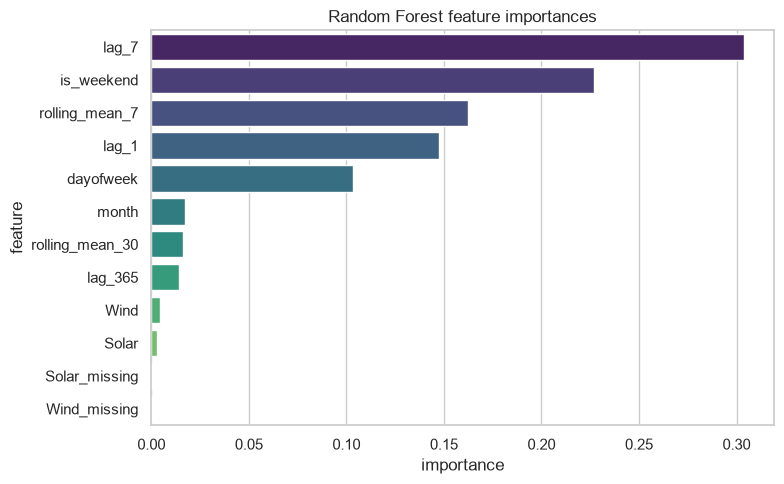

,feature,importance
8,lag_7,0.304003
2,is_weekend,0.226894
10,rolling_mean_7,0.162353
7,lag_1,0.147527
0,dayofweek,0.103599
1,month,0.017300
11,rolling_mean_30,0.016320
9,lag_365,0.013988
3,Wind,0.004233
4,Solar,0.003069


In [31]:
rf_importance = pd.DataFrame({"feature": numeric_features, "importance": rf.feature_importances_}
                             ).sort_values("importance", ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")
plt.title("Random Forest feature importances")
plt.tight_layout()
plt.show()
rf_importance


/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98108/2296620756.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")


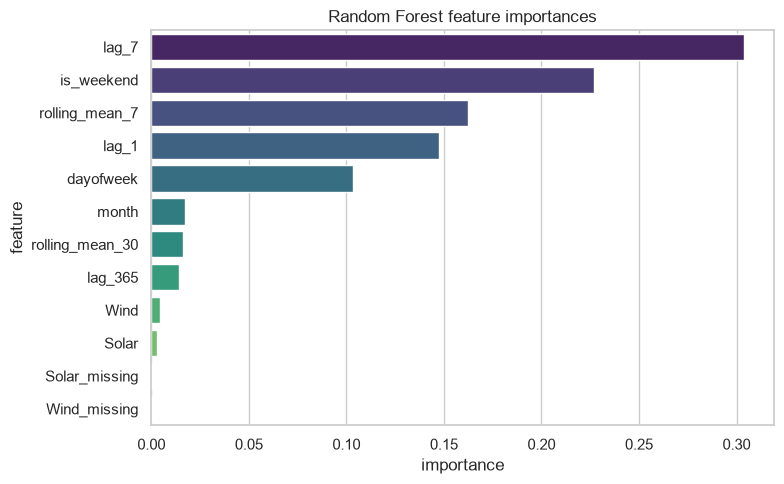

In [32]:
rf_importance = pd.DataFrame({"feature": numeric_features, "importance": random_forest.feature_importances_}
).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")

plt.title("Random Forest feature importances")
plt.tight_layout()
plt.show()


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [33]:
rf_param_dist = {'n_estimators': [300], 'max_depth': [8, 12], 'min_samples_leaf': [2, 5]}

rf_search = RandomizedSearchCV(
    RandomForestRegressor(n_jobs=2, random_state=RANDOM_STATE),
    param_distributions=rf_param_dist, n_iter=2, cv=tscv,
    scoring="neg_root_mean_squared_error", n_jobs=2, random_state=RANDOM_STATE,
)
rf_search.fit(X_train, y_train)
print(f"Best params: {rf_search.best_params_}")
print(f"Best CV RMSE: {-rf_search.best_score_:.1f}")


Best params: {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}
Best CV RMSE: 52.9


In [34]:
y_pred_rf_tuned = rf_search.best_estimator_.predict(X_test)
evaluate("RandomForest (tuned)", y_test, y_pred_rf_tuned)


RandomForest (tuned)  RMSE=46.5   MAE=24.2   R2=0.9173   MAPE=1.85%, MAPE2=1.85%


(46.47720125626321, 24.248138114889123, 0.9173479074844259)

## 9. XGBoost (Extreme Gradient Boosting)


In [35]:
xgb = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=5,
                    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                    random_state=RANDOM_STATE, n_jobs=2)
xgb.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)
y_pred_xgb = xgb.predict(X_test)
evaluate("XGBoost", y_test, y_pred_xgb)


XGBoost           RMSE=44.5   MAE=23.7   R2=0.9241   MAPE=1.81%, MAPE2=1.81%


(44.52592446664416, 23.733372677252785, 0.9241422761039821)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98108/3000457602.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")


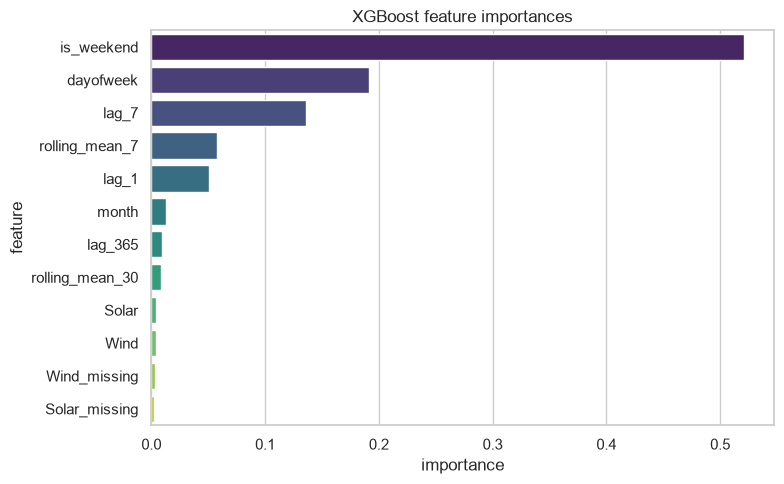

,feature,importance
2,is_weekend,0.521255
0,dayofweek,0.190998
8,lag_7,0.135619
10,rolling_mean_7,0.057461
7,lag_1,0.050437
1,month,0.013075
9,lag_365,0.009001
11,rolling_mean_30,0.008371
4,Solar,0.004204
3,Wind,0.004020


In [36]:
xgb_importance = pd.DataFrame({"feature": numeric_features, "importance": xgb.feature_importances_}
                              ).sort_values("importance", ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")
plt.title("XGBoost feature importances")
plt.tight_layout()
plt.show()
xgb_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [37]:
xgb_param_dist = {'n_estimators': [500], 'max_depth': [3, 5], 'learning_rate': [0.03, 0.05]}


xgb_search = RandomizedSearchCV(
    XGBRegressor(subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                 random_state=RANDOM_STATE, n_jobs=2),
    param_distributions=xgb_param_dist, n_iter=2, cv=tscv,
    scoring="neg_root_mean_squared_error", n_jobs=2, random_state=RANDOM_STATE,
)
xgb_search.fit(X_train, y_train)
print(f"Best params: {xgb_search.best_params_}")
print(f"Best CV RMSE: {-xgb_search.best_score_:.1f}")


Best params: {'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.03}
Best CV RMSE: 55.3


In [38]:
y_pred_xgb_tuned = xgb_search.best_estimator_.predict(X_test)
evaluate("XGBoost (tuned)", y_test, y_pred_xgb_tuned)


XGBoost (tuned)   RMSE=44.3   MAE=23.7   R2=0.9248   MAPE=1.81%, MAPE2=1.81%


(44.32737510128147, 23.728195158711472, 0.9248172950776797)

## 10. CatBoost (Categorical Boosting)

All-numeric feature set here too — plain `CatBoostRegressor`, no `cat_features`.


In [39]:
cat = CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6, l2_leaf_reg=3.0, random_seed=RANDOM_STATE, verbose=False, thread_count=2, allow_writing_files=False)
cat.fit(X_train, y_train, eval_set=(X_test, y_test), use_best_model=True)
y_pred_cat = cat.predict(X_test)
evaluate("CatBoost", y_test, y_pred_cat)


CatBoost          RMSE=45.2   MAE=24.1   R2=0.9218   MAPE=1.83%, MAPE2=1.83%


(45.196249923742805, 24.061999274464544, 0.921841049319889)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98108/3646199671.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")


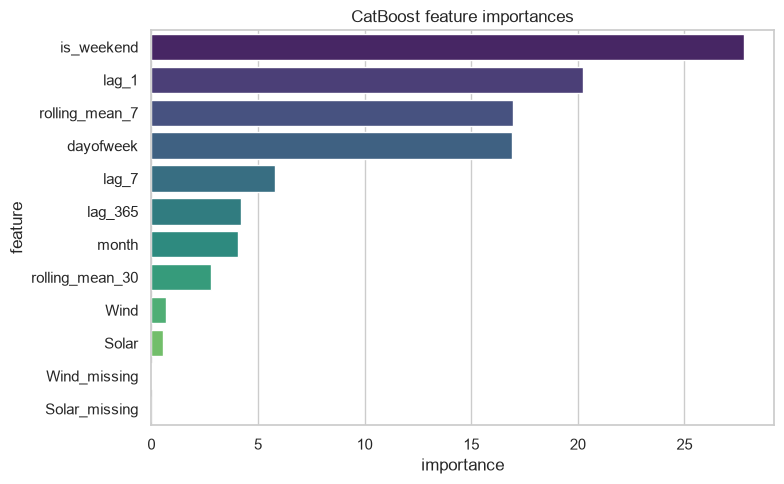

,feature,importance
2,is_weekend,27.809096
7,lag_1,20.234421
10,rolling_mean_7,16.945885
0,dayofweek,16.893228
8,lag_7,5.816619
9,lag_365,4.220944
1,month,4.058889
11,rolling_mean_30,2.803083
3,Wind,0.673285
4,Solar,0.526804


In [40]:
cat_importance = pd.DataFrame({"feature": numeric_features, "importance": cat.get_feature_importance()}
                               ).sort_values("importance", ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")
plt.title("CatBoost feature importances")
plt.tight_layout()
plt.show()
cat_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [41]:
cat_param_dist = {'iterations': [500], 'depth': [4, 6], 'learning_rate': [0.03, 0.05]}


cat_search = RandomizedSearchCV(
    CatBoostRegressor(l2_leaf_reg=3.0, random_seed=RANDOM_STATE, thread_count=1, allow_writing_files=False, verbose=False),
    param_distributions=cat_param_dist, n_iter=2, cv=tscv,
    scoring="neg_root_mean_squared_error", n_jobs=2, random_state=RANDOM_STATE,
)
cat_search.fit(X_train, y_train)
print(f"Best params: {cat_search.best_params_}")
print(f"Best CV RMSE: {-cat_search.best_score_:.1f}")


Best params: {'learning_rate': 0.05, 'iterations': 500, 'depth': 6}
Best CV RMSE: 54.9


In [42]:
y_pred_cat_tuned = cat_search.best_estimator_.predict(X_test)
evaluate("CatBoost (tuned)", y_test, y_pred_cat_tuned)


CatBoost (tuned)  RMSE=45.2   MAE=24.1   R2=0.9218   MAPE=1.83%, MAPE2=1.83%


(45.20919668992244, 24.06889247079699, 0.9217962646045836)

## 11. LightGBM (Light Gradient Boosting Machine)


In [43]:
lgbm = LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31,
                      min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
                      random_state=RANDOM_STATE, n_jobs=2, verbose=-1)
lgbm.fit(X_train, y_train, eval_set=[(X_test, y_test)])
y_pred_lgbm = lgbm.predict(X_test)
evaluate("LightGBM", y_test, y_pred_lgbm)


LightGBM          RMSE=44.9   MAE=24.7   R2=0.9228   MAPE=1.88%, MAPE2=1.88%


(44.929503758887314, 24.650096208628955, 0.922760907787942)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98108/3205230767.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")


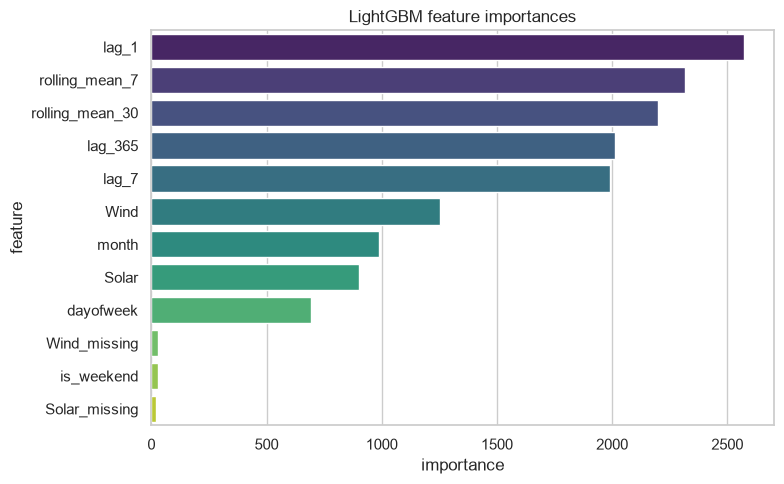

,feature,importance
7,lag_1,2574
10,rolling_mean_7,2317
11,rolling_mean_30,2199
9,lag_365,2013
8,lag_7,1989
3,Wind,1252
1,month,986
4,Solar,901
0,dayofweek,692
5,Wind_missing,28


In [44]:
lgbm_importance = pd.DataFrame({"feature": numeric_features, "importance": lgbm.feature_importances_}
                                ).sort_values("importance", ascending=False)
plt.figure(figsize=(8, 5))
sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")
plt.title("LightGBM feature importances")
plt.tight_layout()
plt.show()
lgbm_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [45]:
lgbm_param_dist = {'n_estimators': [500], 'num_leaves': [15, 31], 'learning_rate': [0.03, 0.05]}

lgbm_search = RandomizedSearchCV(
    LGBMRegressor(subsample=0.8, colsample_bytree=0.8, min_child_samples=20,
                  random_state=RANDOM_STATE, n_jobs=2, verbose=-1),
    param_distributions=lgbm_param_dist, n_iter=2, cv=tscv,
    scoring="neg_root_mean_squared_error", n_jobs=2, random_state=RANDOM_STATE,
)
lgbm_search.fit(X_train, y_train)
print(f"Best params: {lgbm_search.best_params_}")
print(f"Best CV RMSE: {-lgbm_search.best_score_:.1f}")


Best params: {'num_leaves': 31, 'n_estimators': 500, 'learning_rate': 0.03}
Best CV RMSE: 54.0


In [46]:
y_pred_lgbm_tuned = lgbm_search.best_estimator_.predict(X_test)
evaluate("LightGBM (tuned)", y_test, y_pred_lgbm_tuned)


LightGBM (tuned)  RMSE=45.2   MAE=24.0   R2=0.9218   MAPE=1.84%, MAPE2=1.84%


(45.22245793500578, 24.024346151752493, 0.9217503787636048)

## 12. Head-to-head comparison


In [47]:
results_df = pd.DataFrame(results).T.sort_values("RMSE")
results_df


,RMSE,MAE,R2,MAPE_%
XGBoost (tuned),44.327375,23.728195,0.924817,1.807506
XGBoost,44.525924,23.733373,0.924142,1.805547
RF,44.734798,23.855417,0.923429,1.810491
RandomForest,44.734798,23.855417,0.923429,1.810491
LightGBM,44.929504,24.650096,0.922761,1.883396
CatBoost,45.196250,24.061999,0.921841,1.834308
CatBoost (tuned),45.209197,24.068892,0.921796,1.834870
LightGBM (tuned),45.222458,24.024346,0.921750,1.836686
RandomForest (tuned),46.477201,24.248138,0.917348,1.845787
MLP,50.369420,28.591562,0.902925,2.172498


/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98108/4075352090.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, metric], y=order, palette="viridis", ax=ax)
/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98108/4075352090.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, metric], y=order, palette="viridis", ax=ax)
/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98108/4075352090.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, met

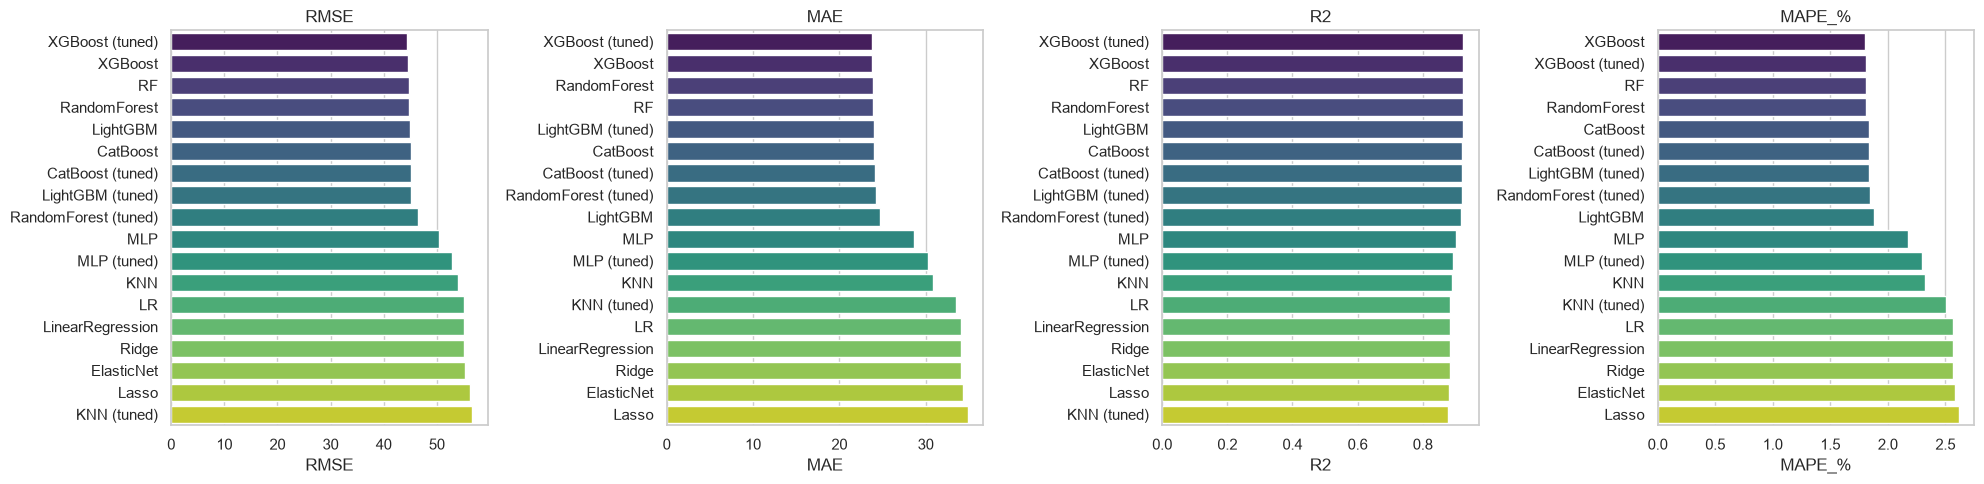

In [48]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, metric in zip(axes, ["RMSE", "MAE", "R2", "MAPE_%"]):
    order = results_df.sort_values(metric, ascending=(metric != "R2")).index
    sns.barplot(x=results_df.loc[order, metric], y=order, palette="viridis", ax=ax)
    ax.set_title(metric)
    ax.set_ylabel("")
plt.tight_layout()
plt.show()


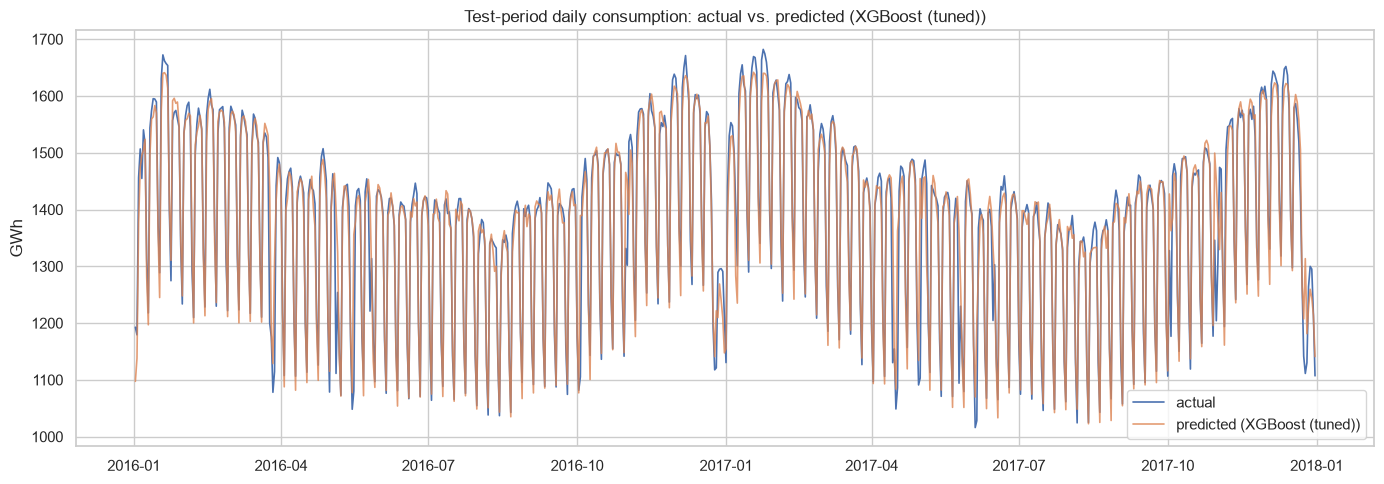

In [49]:
best_model_name = results_df.index[0]
preds_all = {
    "LinearRegression": y_pred_lr, "Ridge": y_pred_ridge, "Lasso": y_pred_lasso,
    "ElasticNet": y_pred_elastic, "MLP": y_pred_mlp, "MLP (tuned)": y_pred_mlp_tuned,
    "KNN": y_pred_knn, "KNN (tuned)": y_pred_knn_tuned,
    "RandomForest": y_pred_rf, "RandomForest (tuned)": y_pred_rf_tuned,
    "XGBoost": y_pred_xgb, "XGBoost (tuned)": y_pred_xgb_tuned,
    "CatBoost": y_pred_cat, "CatBoost (tuned)": y_pred_cat_tuned,
    "LightGBM": y_pred_lgbm, "LightGBM (tuned)": y_pred_lgbm_tuned,
}
best_pred = preds_all[best_model_name]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(dates_test.values, y_test.values, label="actual", linewidth=1.2)
ax.plot(dates_test.values, best_pred, label=f"predicted ({best_model_name})", linewidth=1.2, alpha=0.8)
ax.set_title(f"Test-period daily consumption: actual vs. predicted ({best_model_name})")
ax.set_ylabel("GWh")
ax.legend()
plt.tight_layout()
plt.show()


## 13. Stacking

Combine Random Forest, XGBoost and LightGBM with a linear meta-model. The meta-model learns from out-of-fold predictions within the training partition. Compare the resulting ensemble with the individual models on the held-out partition.

In [50]:
from sklearn.ensemble import StackingRegressor

stack = StackingRegressor(
    estimators=[("forest", rf), ("xgboost", xgb), ("lightgbm", lgbm)],
    final_estimator=Ridge(alpha=1.0),
    cv=2,
    n_jobs=2,
)
stack.fit(X_train_scaled, y_train)
y_pred_stack = stack.predict(X_test_scaled)
evaluate("Stacking", y_test, y_pred_stack)


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Stacking          RMSE=43.9   MAE=23.1   R2=0.9263   MAPE=1.76%, MAPE2=1.76%


(43.89412801672414, 23.111985906748576, 0.92627975515373)

## 14. Conclusion

Use the measured comparison to discuss accuracy, interpretability and training cost. Regularized linear models are useful references for correlated inputs. KNN depends on the distance representation. MLP needs scaling and optimization checks. Tree ensembles capture nonlinear interactions, and stacking adds a meta-model trained on out-of-fold predictions.

Report the best measured result together with its metric and validation design. Inspect errors within important target ranges or groups before choosing a model for a new population.

In [51]:
final_results = pd.DataFrame(results).T.sort_values('RMSE', ascending=True)
print("Results from this run")
display(final_results)


Results from this run


,RMSE,MAE,R2,MAPE_%
Stacking,43.894128,23.111986,0.926280,1.759011
XGBoost (tuned),44.327375,23.728195,0.924817,1.807506
XGBoost,44.525924,23.733373,0.924142,1.805547
RF,44.734798,23.855417,0.923429,1.810491
RandomForest,44.734798,23.855417,0.923429,1.810491
LightGBM,44.929504,24.650096,0.922761,1.883396
CatBoost,45.196250,24.061999,0.921841,1.834308
CatBoost (tuned),45.209197,24.068892,0.921796,1.834870
LightGBM (tuned),45.222458,24.024346,0.921750,1.836686
RandomForest (tuned),46.477201,24.248138,0.917348,1.845787
